## {Gaussian, Uniform} to 8-Gaussian, guidance with Learned, MC, CEG

In [21]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

from functools import partial
from typing import List, Tuple
from guided_flow.backbone.mlp import MLP, ClassConditionalMLP, CondMLP
from guided_flow.backbone.wrapper import ExpEnergyMLPWrapper, GuidedMLPWrapper, MLPWrapper, ClassConditionalMLPWrapper
from guided_flow.config.sampling import GuideFnConfig
from guided_flow.distributions.base import BaseDistribution, get_distribution
from guided_flow.distributions.gaussian import GaussianDistribution
from guided_flow.flow.optimal_transport import OTPlanSampler
from guided_flow.guidance.gradient_guidance import wrap_grad_fn
from guided_flow.utils.misc import deterministic
from guided_flow.utils.metrics import compute_w2 as w2
import torch
from torchdyn.core import NeuralODE
import numpy as np
from torch.distributions import Normal, Independent
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pathlib import Path
import os, glob
from tqdm import tqdm
from guided_flow.config.sampling import ODEConfig


from guided_flow.utils.kl_divergence import compute_kl_divergence
MLP_WIDTH = 256
MLP_WIDTH_CCFM = 512
TRAINING_B = 256 # OT CFM training batch size


def get_latest_model(base_dir, prefix):
    """
    Searches for all .pth files matching the prefix and returns the latest one.
    """
    search_pattern = os.path.join(base_dir, f"{prefix}*.pth")
    files = glob.glob(search_pattern)
    
    if not files:
        raise FileNotFoundError(f"Could not find any models matching: {search_pattern}")
    
    # Sorting alphabetically works perfectly because of the YYYYMMDD_HHMMSS format
    latest_file = sorted(files)[-1]
    print(f"Loaded latest model: {os.path.basename(latest_file)}")
    
    return latest_file


def sample_x1_frompeJ(x1_sampler, x1_dist, device, B):
    x1 = None
    while x1 is None or x1.shape[0] < B:
        x1_ = x1_sampler(B).to(device)
        weights = torch.exp(-x1_dist.get_J(x1_))
        acc_prob = weights / weights.max()
        random_numbers = torch.rand(B, device=device)
        x1_ = x1_[random_numbers < acc_prob]
        if x1 is None:
            x1 = x1_
        else:
            x1 = torch.cat([x1, x1_], 0)
    x1 = x1[:B]
    return x1


def compute_w2(trajs, cfgs: List[GuideFnConfig]):
    w2s = []
    for traj, cfg in zip(trajs, cfgs):
        x0_dist = get_distribution(cfg.dist_pair[0])
        x1_dist = get_distribution(cfg.dist_pair[1])
        
        x1 = sample_x1_frompeJ(x1_dist.sample, x1_dist, cfg.ode_cfg.device, cfg.ode_cfg.batch_size)
        w2s.append(w2(traj[-1], x1))
    return w2s


def get_mc_guide_fn(x0_dist: BaseDistribution, x1_dist: BaseDistribution, mc_cfg: GuideFnConfig, cfm: str):

    def log_cfm_p_t1(x1, xt, t):
        # xt = t x1 + (1 - t) x0 -> x0 = xt / (1 - t) - t / (1 - t) x1
        x0 = xt / (1 - t + mc_cfg.ep) - (t + mc_cfg.ep) / (1 - t + mc_cfg.ep) * x1 # (B, 2)
        p1t = x0_dist.prob(x0).clamp(1e-8) / (1 - t[0] + mc_cfg.ep) ** 2 # (B,)
        log_p1t = p1t.log()
        # print(log_p1t.mean())
        return log_p1t
        
    def guide_fn(t, x, dx_dt, model, x0=None, x1=None, Jx1=None):
        """
        Args:
            t: Tensor, shape (b, 1)
            x: Tensor, shape (b, dim)
            dx_dt: Tensor, shape (b, dim)
            model: MLP
        """
        # estimate E (e^{-J} / Z - 1) * u
        b = x.shape[0]
        B = mc_cfg.mc_batch_size
        x_ = x.repeat(B, 1) # (MC_B * b, 2)
        t_ = t.repeat(B * b, 1) # (MC_B * b)
        if cfm == 'cfm':
            log_p_t1_x = log_cfm_p_t1(x1, x_, t_) # (MC_B * b) # TODO
            log_p_t_x = log_p_t1_x.reshape(B, b, 1).logsumexp(0) - torch.log(torch.tensor(B, device=x.device)) # (MC_B, B, 1) -> (B, 1)
            log_p_t1_x_times_J_ = (log_p_t1_x + torch.log(Jx1)).reshape(B, b, 1) # (MC_B * b) -> (MC_B, b, 1)            
            logZ = torch.logsumexp(log_p_t1_x_times_J_, 0) - torch.log(torch.tensor(B, device=x.device)) - log_p_t_x # (b, 1)

            Z = torch.exp(logZ)
            u = (x1 - x_) / (1 - t_ + mc_cfg.ep) # (MC_B * b, dim)

            g = (log_p_t1_x.reshape(B, b, 1) - log_p_t_x.unsqueeze(0)).exp() * (Jx1.reshape(B, b, 1) / (Z + 1e-8).unsqueeze(0) - 1) * u.reshape(B, b, 2) # (MC_B, b, dim)

            return g.mean(0)

    
    x1 = x1_dist.sample(mc_cfg.mc_batch_size).to(mc_cfg.ode_cfg.device).unsqueeze(0).repeat(mc_cfg.ode_cfg.batch_size, 1, 1).permute(1, 0, 2).reshape(-1, 2)
    Jx1 = torch.exp(-mc_cfg.scale * x1_dist.get_J(x1))
    return partial(
        guide_fn, 
        x1=x1, 
        Jx1=Jx1
    )

def get_guide_fn(dist: BaseDistribution, cfg: GuideFnConfig):
    def guide_fn(t, x, dx_dt, model):

        if cfg.guide_type == 'g_cov_A':
            x1_pred = x + dx_dt * (1 - t)
            J = dist.get_J(x1_pred)
            try:
                with torch.enable_grad():
                    x1_pred = x1_pred.requires_grad_(True)
                    J = dist.get_J(x1_pred)
                    grad = -torch.autograd.grad(J.sum(), x1_pred, create_graph=True)[0]
                    return grad
            except Exception as e:
                return torch.zeros_like(x)
        
        elif cfg.guide_type == 'g_cov_G':
            with torch.enable_grad():
                x = x.requires_grad_(True)
                x1_pred = x + model(torch.cat([x, t.repeat(x.shape[0])[:, None]], 1)) * (1 - t)
                J = dist.get_J(x1_pred)
                try:
                    grad = -torch.autograd.grad(J.sum(), x, create_graph=True)[0]
                    return grad
                except Exception as e:
                    return torch.zeros_like(x)
        else:
            raise ValueError(f"Unknown guide function: {cfg.guide_type}")
    # make scale and schedule
    return wrap_grad_fn(cfg.guide_scale, cfg.guide_schedule, guide_fn)

def get_sim_mc_guide_fn(x1_dist: BaseDistribution, cfg: GuideFnConfig):
    def guide_fn(t, x, dx_dt, model):
        """
        Implements guidance following Eq. 12
        Args:
            t: flow time. float
            x: current sample x_t. Tensor, shape (b, dim)
            dx_dt: current predicted VF. Tensor, shape (b, dim)
            model: flow model. MLP
        """
        x1_pred = x + dx_dt * (1 - t) # (B, 2)
        std = cfg.sim_mc_std
        
        x1 = torch.randn_like(x1_pred.unsqueeze(0).repeat(cfg.sim_mc_n, 1, 1)) * std + x1_pred # (cfg.sim_mc_n, B, 2)
        Jx1_ = torch.exp(-cfg.scale * x1_dist.get_J(x1.reshape(-1, 2))).reshape(cfg.sim_mc_n, -1) # (cfg.sim_mc_n, B)
        v = (x1 - x) / (1 - t + cfg.ep)  # Conditional VF v_{t|z} in Eq. 12 (cfg.sim_mc_n, B, 2)
        Z = Jx1_.mean(0) + 1e-8  # Z in Eq. 12 (B,)
        g = (Jx1_ / Z - 1).unsqueeze(2) * v  # g in Eq. 12 (cfg.sim_mc_n, B, 2)
        return g.mean(0)
    return wrap_grad_fn(cfg.guide_scale, cfg.guide_schedule, guide_fn)

def evaluate(x0_sampler, x1_sampler, model, guide_fn, cfg: ODEConfig):
    node = NeuralODE(
        GuidedMLPWrapper(
            model, 
            guide_fn=guide_fn,
            scheduler=lambda t: 1
        ), 
        solver="euler", sensitivity="adjoint")

    with torch.no_grad():
        traj = node.trajectory(
            x0_sampler(cfg.batch_size).to(cfg.device), 
            t_span=torch.linspace(0, cfg.t_end, cfg.num_steps)
        )
    
    return traj


def sample_and_compute_w2(guide_cfgs: List[GuideFnConfig]):
    print("Monte Carlo batch size:", guide_cfgs[0].mc_batch_size)

    trajs = []

    for cfg in guide_cfgs:

        # Initialize samplers, model and guidance model
        x0_dist = get_distribution(cfg.dist_pair[0])
        x1_dist = get_distribution(cfg.dist_pair[1])

        x0_sampler = x0_dist.sample
        x1_sampler = x1_dist.sample

        model = MLP(dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
    
        # Define the base directory where the models for this pair are saved
        log_dir = f'../logs/{cfg.dist_pair[0]}-{cfg.dist_pair[1]}/{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}/'
        
        # Define the prefix for the base model (everything before the timestamp)
        prefix = f'{cfg.cfm}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}'
        
        # Grab the newest file automatically
        latest_cfm_path = get_latest_model(log_dir, prefix)
        
        # Load the weights
        model.load_state_dict(torch.load(latest_cfm_path, map_location='cpu', weights_only=True))
        if cfg.guide_type == 'mc':
            # sample using flow model
            traj = evaluate(x0_sampler, x1_sampler, model, get_mc_guide_fn(x0_dist, x1_dist, cfg, cfg.cfm), cfg.ode_cfg)
            
        elif cfg.guide_type == 'learned':
            model_G = MLP(dim=2, out_dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.ode_cfg.device)
            gm_prefix = f'guidance_matching_{cfg.gm_type}_scale_{cfg.scale}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}'
            latest_gm_path = get_latest_model(log_dir, gm_prefix)
            model_G.load_state_dict(torch.load(latest_gm_path, map_location='cpu', weights_only=True))
            traj = evaluate(x0_sampler, x1_sampler, model, MLPWrapper(model_G, scheduler=lambda t: 1., clamp=0), cfg.ode_cfg)
        
        elif cfg.guide_type == 'ceg':
            model_Z = MLP(dim=2, out_dim=1, w=MLP_WIDTH, time_varying=True, exp_final=False).to(cfg.ode_cfg.device)
            ceg_prefix = f'ceg_scale_{cfg.scale}_{cfg.dist_pair[0]}_{cfg.dist_pair[1]}'
            latest_ceg_path = get_latest_model(log_dir, ceg_prefix)
            model_Z.load_state_dict(torch.load(latest_ceg_path, map_location='cpu', weights_only=True))
            
            # 2D xy plane. make uniform grid
            XX = torch.linspace(0, 1, 100)
            YY = torch.linspace(0, 1, 100)
            # Use 'xy' indexing so it matches standard cartesian plotting
            XX, YY = torch.meshgrid(XX, YY, indexing='xy') 
            xy = torch.stack([XX.flatten(), YY.flatten()], 1)
            t = torch.zeros(10000, 1) + 0.9
            
            # Calculate the energy landscape
            Z_grid = model_Z(torch.cat([xy, t], 1).to(cfg.ode_cfg.device)).detach().cpu().numpy().reshape(100, 100)
            
            # Plot with correct coordinate mapping
            fig, ax = plt.subplots(figsize=(6, 5))
            
            # Use extent=[xmin, xmax, ymin, ymax] to map indices back to 0-1
            img = ax.imshow(Z_grid, extent=[0, 1, 0, 1], origin='lower', cmap='viridis', aspect='auto')
            
            # Add descriptive labels
            ax.set_title(f"CEG Learned Energy Landscape Z(x, t=0.9)\n{cfg.dist_pair[0]} -> {cfg.dist_pair[1]}")
            ax.set_xlabel("X Coordinate")
            ax.set_ylabel("Y Coordinate")
            fig.colorbar(img, ax=ax, label="Learned Scalar Value Z")
            
            plt.show() # Display it cleanly before returning the trajectory
            
            traj = evaluate(x0_sampler, x1_sampler, model, ExpEnergyMLPWrapper(model_Z, scheduler=lambda t: 1, clamp=1), cfg.ode_cfg)
        elif cfg.guide_type in ['g_cov_A', 'g_cov_G']:
            traj = evaluate(x0_sampler, x1_sampler, model, get_guide_fn(x1_dist, cfg), cfg.ode_cfg)

        elif cfg.guide_type == 'g_sim_MC':
            traj = evaluate(x0_sampler, x1_sampler, model, get_sim_mc_guide_fn(x1_dist, cfg), cfg.ode_cfg)
        trajs.append(traj)
    return trajs, None

deterministic(0)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
guide_cfgs_mc_cfm = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), mc_batch_size=10240, ep=5e-2, scale=1, ode_cfg=ODEConfig(t_end=0.95, num_steps=200)), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), mc_batch_size=10240, ep=1e-3, ode_cfg=ODEConfig(t_end=1, num_steps=200)), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), mc_batch_size=1024, ep=1e-2, scale=1, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
]

deterministic(0)
trajs_mc_cfm, w2s_mc_cfm = sample_and_compute_w2(guide_cfgs_mc_cfm)
compute_w2(trajs_mc_cfm, guide_cfgs_mc_cfm)


Monte Carlo batch size: 10240
Loaded latest model: cfm_circle_s_curve_20260603_133620.pth
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: cfm_8gaussian_moon_20260603_133626.pth


[np.float64(0.49820709015293085),
 np.float64(0.39295568076516674),
 np.float64(0.8870020606266811)]

In [23]:
guide_cfgs_gm_cfm = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), guide_type='learned', ep=1e-2, gm_type='g3', ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='learned', ep=1e-3, gm_type='g3', ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), guide_type='learned', ep=1e-2, gm_type='g3', ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
]

trajs_gm_cfm, w2s_gm_cfm = sample_and_compute_w2(guide_cfgs_gm_cfm)
compute_w2(trajs_gm_cfm, guide_cfgs_gm_cfm)


Monte Carlo batch size: 1024
Loaded latest model: cfm_circle_s_curve_20260603_133620.pth
Loaded latest model: guidance_matching_g3_scale_1.0_circle_s_curve.pth
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: guidance_matching_g3_scale_1.0_uniform_8gaussian_20260608_184444.pth
Loaded latest model: cfm_8gaussian_moon_20260603_133626.pth
Loaded latest model: guidance_matching_g3_scale_1.0_8gaussian_moon.pth


[np.float64(0.5838180209566722),
 np.float64(0.04604737360222872),
 np.float64(0.6526162920438802)]

Monte Carlo batch size: 1024
Loaded latest model: cfm_circle_s_curve_20260603_133620.pth
Loaded latest model: ceg_scale_1.0_circle_s_curve.pth


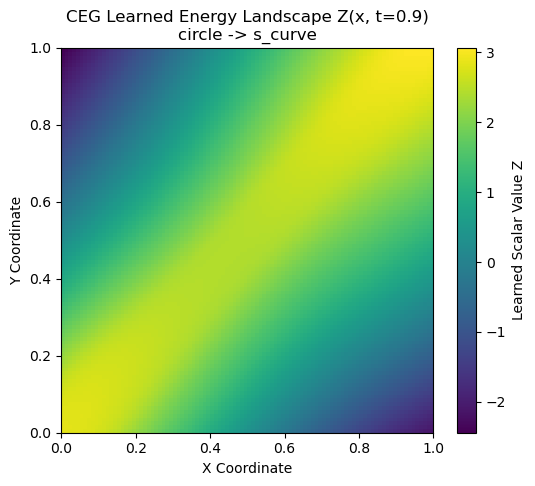

Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: ceg_scale_1.0_uniform_8gaussian_20260608_192344.pth


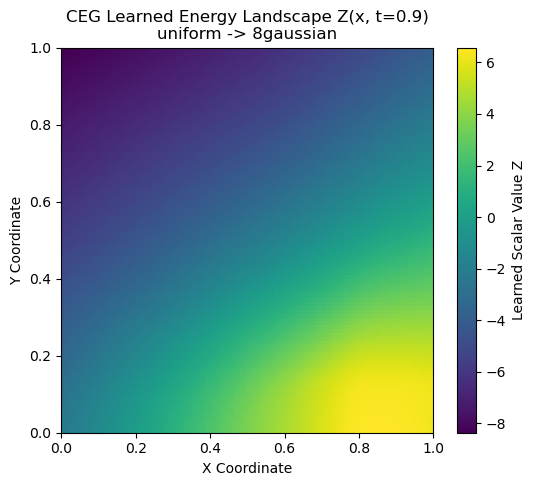

Loaded latest model: cfm_8gaussian_moon_20260603_133626.pth
Loaded latest model: ceg_scale_1.0_8gaussian_moon.pth


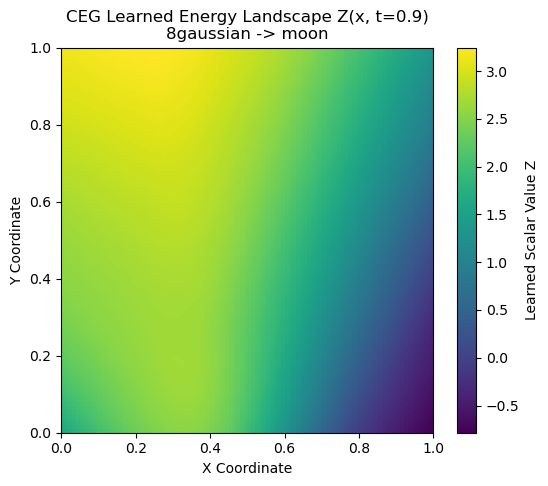

[np.float64(0.3321695486116538),
 np.float64(0.7416042413393477),
 np.float64(0.5943124371003669)]

In [24]:
guide_cfgs_ceg_cfm = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), guide_type='ceg', ep=1e-2, ode_cfg=ODEConfig(t_end=0.95, num_steps=200)), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='ceg', ep=1e-3, ode_cfg=ODEConfig(t_end=0.95, num_steps=200)), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), guide_type='ceg', ep=1e-2, ode_cfg=ODEConfig(t_end=0.95, num_steps=200)), 
]

trajs_ceg_cfm, w2s_ceg_cfm = sample_and_compute_w2(guide_cfgs_ceg_cfm)
compute_w2(trajs_ceg_cfm, guide_cfgs_ceg_cfm)


In [25]:
guide_cfgs_g_cov_a_cfm = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), guide_type='g_cov_A', guide_scale=0.2, guide_schedule='exp_decay', ep=1e-2, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_cov_A', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), guide_type='g_cov_A', guide_scale=2.0, guide_schedule='linear_decay', ep=1e-2, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
]

trajs_g_cov_a_cfm, w2s_g_cov_a_cfm = sample_and_compute_w2(guide_cfgs_g_cov_a_cfm)
compute_w2(trajs_g_cov_a_cfm, guide_cfgs_g_cov_a_cfm)


Monte Carlo batch size: 1024
Loaded latest model: cfm_circle_s_curve_20260603_133620.pth
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: cfm_8gaussian_moon_20260603_133626.pth


[np.float64(0.3521926154277862),
 np.float64(0.10166011186428366),
 np.float64(0.7253337152947945)]

In [26]:
guide_cfgs_g_cov_g_cfm = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), guide_type='g_cov_G', guide_scale=0.2, guide_schedule='exp_decay', ep=1e-2, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_cov_G', guide_scale=1.0, guide_schedule='linear_decay', ep=1e-3, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), guide_type='g_cov_G', guide_scale=2.0, guide_schedule='linear_decay', ep=1e-2, ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
]

trajs_g_cov_g_cfm, w2s_g_cov_g_cfm = sample_and_compute_w2(guide_cfgs_g_cov_g_cfm)
compute_w2(trajs_g_cov_g_cfm, guide_cfgs_g_cov_g_cfm)


Monte Carlo batch size: 1024
Loaded latest model: cfm_circle_s_curve_20260603_133620.pth
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: cfm_8gaussian_moon_20260603_133626.pth


[np.float64(0.3240515518278536),
 np.float64(0.10355988773011501),
 np.float64(0.7426639786527951)]

In [27]:
guide_cfgs_g_sim_MC_cfm = [
    GuideFnConfig(dist_pair=('circle', 's_curve'), guide_type='g_sim_MC', sim_mc_std=1, sim_mc_n=100, ep=1e-2, guide_scale=2.0, guide_schedule='linear_decay', ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('uniform', '8gaussian'), guide_type='g_sim_MC', sim_mc_std=1, sim_mc_n=100, ep=1e-2, guide_scale=1, guide_schedule='linear_decay', ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
    GuideFnConfig(dist_pair=('8gaussian', 'moon'), guide_type='g_sim_MC', sim_mc_std=0.5, sim_mc_n=100, ep=1e-2, guide_scale=1, guide_schedule='linear_decay', ode_cfg=ODEConfig(t_end=1.0, num_steps=200)), 
]

trajs_g_sim_MC_cfm, w2s_g_sim_MC_cfm = sample_and_compute_w2(guide_cfgs_g_sim_MC_cfm)
compute_w2(trajs_g_sim_MC_cfm, guide_cfgs_g_sim_MC_cfm)


Monte Carlo batch size: 1024
Loaded latest model: cfm_circle_s_curve_20260603_133620.pth
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: cfm_8gaussian_moon_20260603_133626.pth


[np.float64(0.30919876376959304),
 np.float64(0.4293995739224515),
 np.float64(0.5548068110040153)]

In [28]:
def sample_cc_cfm(model, cfg, class_probs=None):
    """
    Samples from the Class-Conditional Flow Matching model.
    
    Args:
        model: The trained ClassConditionalMLP.
        cfg: The GuideFnConfig containing dataset pairs and ODE parameters.
        class_probs: Optional tensor of probabilities for each of the 8 classes. 
                     If None, it generates classes uniformly (12.5% each).
    """
    device = cfg.ode_cfg.device
    B = cfg.ode_cfg.batch_size
    
    # 1. Handle Class Distributions
    if class_probs is not None:
        # Sample classes based on the provided empirical distribution
        y_target = torch.multinomial(class_probs, B, replacement=True).to(device)
    else:
        # Fallback to uniform distribution across the 8 classes
        y_target = torch.arange(8).repeat_interleave(B // 8).to(device)
        # Pad if batch size is not perfectly divisible by 8
        if len(y_target) < B:
            pad = torch.zeros(B - len(y_target), dtype=torch.long, device=device)
            y_target = torch.cat([y_target, pad])
            
    # 2. Setup ODE Wrapper
    wrapper = ClassConditionalMLPWrapper(model, y=y_target)
    node = NeuralODE(wrapper, solver="euler", sensitivity="adjoint")
    
    # 3. Sample from source distribution
    x0_dist = get_distribution(cfg.dist_pair[0]) 
    x0 = x0_dist.sample(B).to(device)
    
    # 4. Integrate
    with torch.no_grad():
        traj = node.trajectory(
            x0, 
            t_span=torch.linspace(0, cfg.ode_cfg.t_end, cfg.ode_cfg.num_steps).to(device)
        )
        
    return traj

In [29]:
def plot_traj(trajs, cfgs: List[GuideFnConfig], disp_b, skip_ref=False, nmethods=7):
    blue = plt.get_cmap('coolwarm', 2)(0)
    red = plt.get_cmap('coolwarm', 2)(1)
    
    ndata = 3
    ncols = nmethods + 2
    
    # visualize, no VF
    fig, axs = plt.subplots(ndata, ncols) 
    r = 6
    # Scale figure size dynamically based on number of columns
    fig.set_size_inches(ncols * r, ndata * r)
    
    size_ratio = 0.7
    
    # 1. plot ref distributions
    for i in range(ndata):
        if skip_ref:
            break
        # Always grab the 0th configuration of the row to establish limits
        row_cfg = cfgs[i * nmethods]
        
        x0_dist = get_distribution(row_cfg.dist_pair[0])
        x1_dist = get_distribution(row_cfg.dist_pair[1])
        x0_sampler = x0_dist.sample
        x1_sampler = x1_dist.sample
        x1 = x1_sampler(1024).to(row_cfg.ode_cfg.device)
        
        ax = axs[i, 0]
        ax.scatter(x1[:, 0].cpu(), x1[:, 1].cpu(), s=3, color=red)
        ax.set_xlim(-row_cfg.xlim * size_ratio, row_cfg.xlim * size_ratio)
        ax.set_ylim(-row_cfg.ylim * size_ratio, row_cfg.ylim * size_ratio)
        ax.axis('off')
        ax.set_aspect('auto')

        ax = axs[i, 1]
        # use rejection sampling to sample with weight e^-J in x1
        x1 = sample_x1_frompeJ(x1_sampler, x1_dist, row_cfg.ode_cfg.device, 1024)
        ax.scatter(x1[:, 0].cpu(), x1[:, 1].cpu(), s=3, color=red)
        ax.set_xlim(-row_cfg.xlim * size_ratio, row_cfg.xlim * size_ratio)
        ax.set_ylim(-row_cfg.ylim * size_ratio, row_cfg.ylim * size_ratio)
        ax.set_ylabel(x0_dist.__name__() + '$\\rightarrow$' + x1_dist.__name__())
        ax.axis('off')
        ax.set_aspect('auto')


    # 2. plot different methods
    for i in range(ndata):
        # We need the row's base config to ensure limits are consistent across the whole row
        row_cfg = cfgs[i * nmethods] 
        
        for j in range(nmethods):
            ax = axs[i, j + 2]
            
            # Apply consistent limits to EVERY plot in the row, even empty ones
            ax.set_xlim(-row_cfg.xlim * size_ratio, row_cfg.xlim * size_ratio)
            ax.set_ylim(-row_cfg.ylim * size_ratio, row_cfg.ylim * size_ratio)
            ax.axis('off')
            ax.set_aspect('auto')
            
            try:
                traj = trajs[i * nmethods + j]
                cfg = cfgs[i * nmethods + j]
                
                # Safely skip the None placeholders we added, leaving a blank square
                if traj is None or cfg is None:
                    continue
            except IndexError:
                continue
            
            idx = torch.randperm(cfg.ode_cfg.batch_size)[:disp_b]
            
            # plot the start and end points with endpoint colors in the colormap
            ax.scatter(traj[0, :, 0].cpu(), traj[0, :, 1].cpu(), s=3, color=blue)
            ax.scatter(traj[-1, :, 0].cpu(), traj[-1, :, 1].cpu(), s=3, color=red)
            
            # plot the trajectory with a gradient color
            colors = torch.linspace(0, 1, cfg.ode_cfg.num_steps).unsqueeze(1).repeat(1, disp_b).flatten().numpy()
            ax.scatter(
                traj[:, idx, 0].flatten().cpu(), 
                traj[:, idx, 1].flatten().cpu(), 
                c=plt.cm.coolwarm(colors), 
                alpha=0.5, s=0.1, marker='.'
            )
            
    return fig

In [47]:
# 1. Ensure the correct configuration is selected
cfg_row2 = guide_cfgs_mc_cfm[1]
device = cfg_row2.ode_cfg.device

# 2. Evaluate empirical class probabilities
x1_dist = get_distribution(cfg_row2.dist_pair[1])
gt_x1 = sample_x1_frompeJ(x1_dist.sample, x1_dist, device, B=50000)

angles = torch.atan2(gt_x1[:, 1], gt_x1[:, 0])
gt_y = torch.round((angles + torch.pi) / (torch.pi / 4)) % 8
# gt_y = x1_dist.get_J(gt_x1)
class_counts = torch.bincount(gt_y.long().to(device), minlength=8)
class_probs = class_counts.float() / class_counts.sum()

# 3. Load CC-CFM Model
cc_model = ClassConditionalMLP(
    dim=2, 
    num_classes=8, 
    class_emb_dim=16, # Must match what you used in train.py!
    w=MLP_WIDTH_CCFM, 
    time_varying=True, 
    time_embedding=True
).to(device)
# Define the base directory using Path, but convert to string for the helper function
log_dir = str(Path.cwd().parent / "logs" / "uniform-8gaussian" / "cc_cfm_uniform_8gaussian")

# Define the prefix. (This will catch files named 'cc_cfm_uniform_8gaussian_best_TIMESTAMP.pth' 
# or just 'cc_cfm_uniform_8gaussian_TIMESTAMP.pth')
cc_prefix = "cc_cfm_uniform_8gaussian"

# Grab the newest file automatically
latest_cc_path = get_latest_model(log_dir, cc_prefix)

print(latest_cc_path)

# Load the weights
cc_model.load_state_dict(torch.load(latest_cc_path, map_location=device))
cc_model.eval()

# 4. Generate the missing traj_cc_cfm!
print(f"Sampling CC-CFM Baseline...")
traj_cc_cfm = sample_cc_cfm(cc_model, cfg_row2, class_probs=class_probs)

Loaded latest model: cc_cfm_uniform_8gaussian_20260610_163125.pth
/Users/LS/Documents/Studium/8-SS26/Deep Learning Seminar/own Project/Guided-Flow-Matching-for-CellOT/synthetic/logs/uniform-8gaussian/cc_cfm_uniform_8gaussian/cc_cfm_uniform_8gaussian_20260610_163125.pth
Sampling CC-CFM Baseline...


/var/folders/gv/wx9sfw953yj9n5_h3jd_8srh0000gq/T/ipykernel_85011/4006679449.py:37: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  cc_model.load_state_dict(torch.load(latest_c

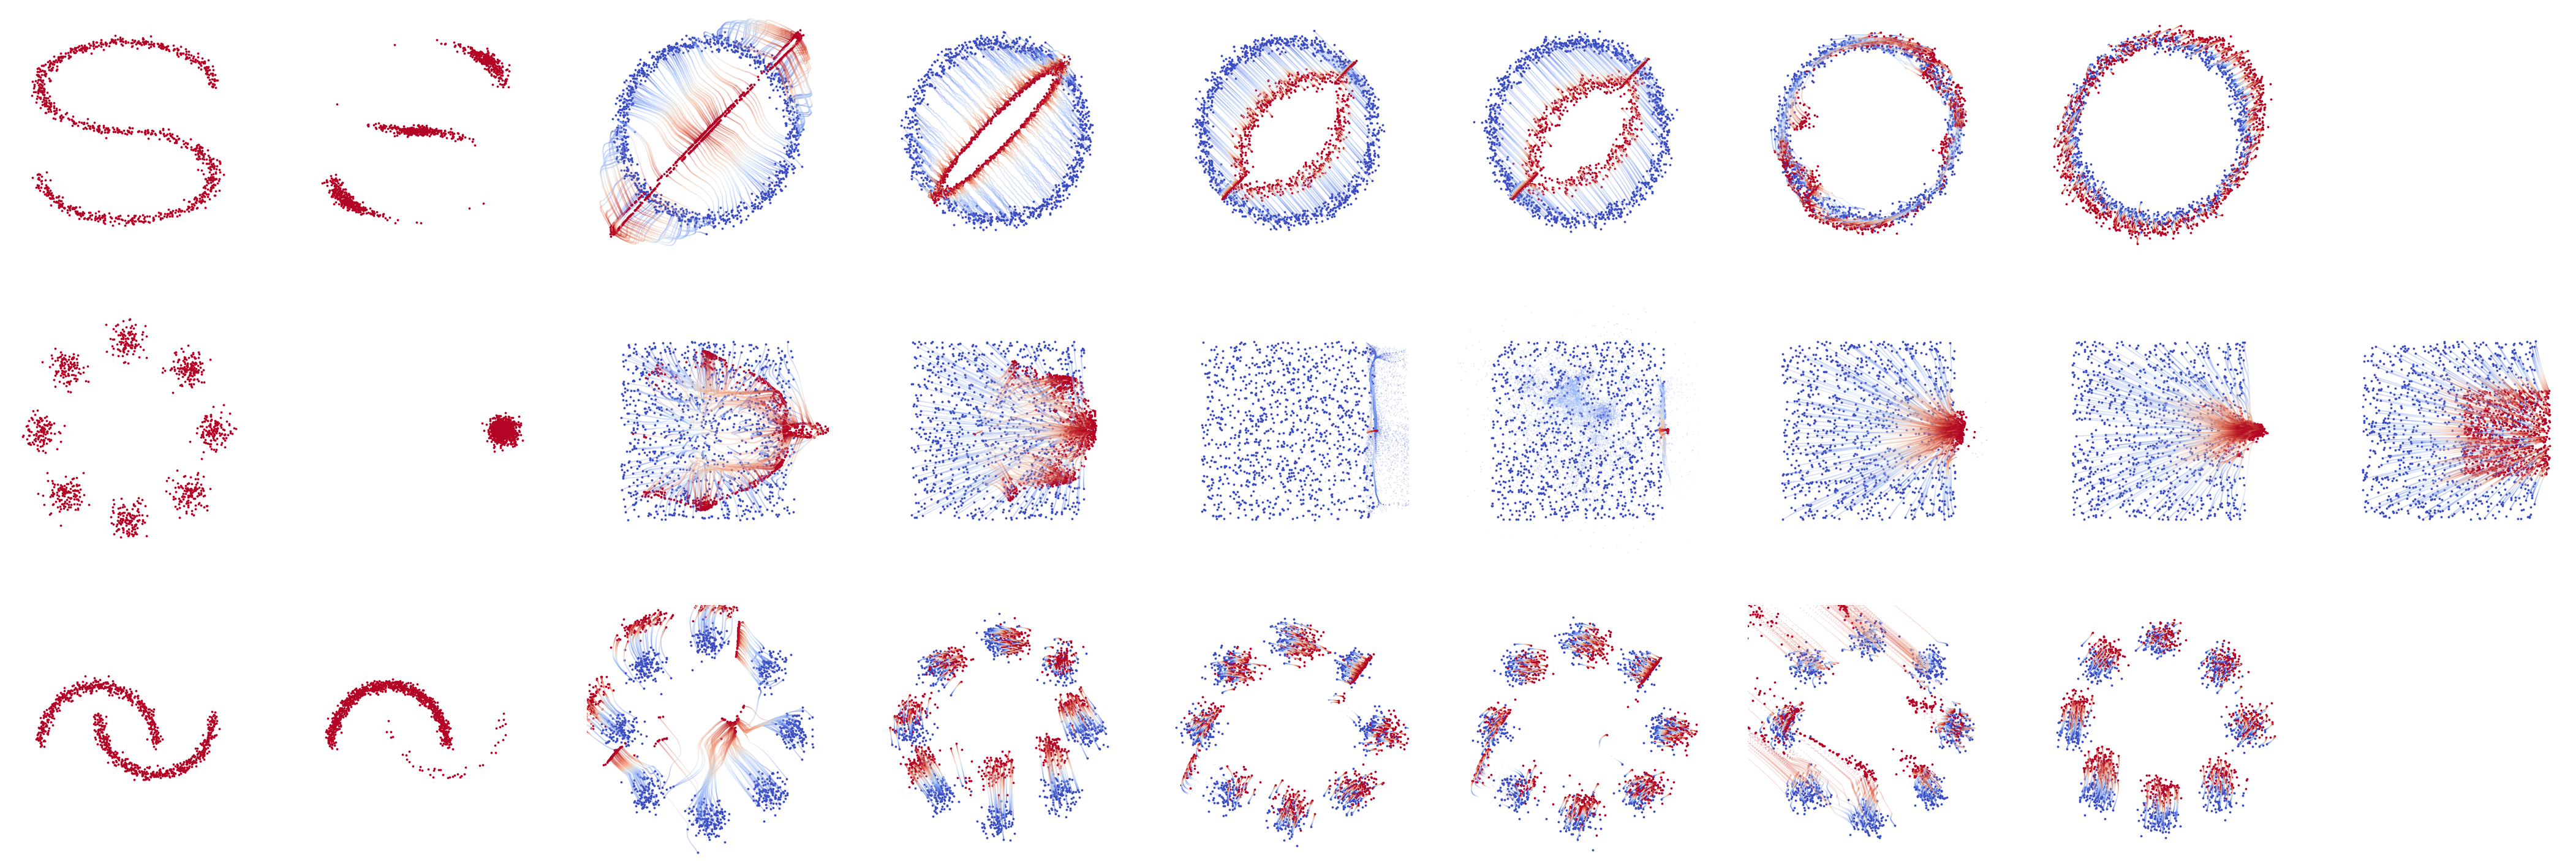

In [31]:
def transpose(lst):
    return [list(i) for i in zip(*lst)]
def flatten(lst):
    return [item for sublist in lst for item in sublist]

# Reconstruct the grid explicitly row-by-row to prevent list shifting

# Row 1: circle -> s_curve (No CC-CFM baseline here, so we pass None)
trajs_row1 = [trajs_ceg_cfm[0], trajs_g_sim_MC_cfm[0], trajs_g_cov_a_cfm[0], trajs_g_cov_g_cfm[0], trajs_mc_cfm[0], trajs_gm_cfm[0], None]
cfgs_row1 = [guide_cfgs_ceg_cfm[0], guide_cfgs_g_sim_MC_cfm[0], guide_cfgs_g_cov_a_cfm[0], guide_cfgs_g_cov_g_cfm[0], guide_cfgs_mc_cfm[0], guide_cfgs_gm_cfm[0], None]

# Row 2: uniform -> 8gaussian (We inject our gaussian -> 8gaussian CC-CFM baseline here)
trajs_row2 = [trajs_ceg_cfm[1], trajs_g_sim_MC_cfm[1], trajs_g_cov_a_cfm[1], trajs_g_cov_g_cfm[1], trajs_mc_cfm[1], trajs_gm_cfm[1], traj_cc_cfm]
cfgs_row2 = [guide_cfgs_ceg_cfm[1], guide_cfgs_g_sim_MC_cfm[1], guide_cfgs_g_cov_a_cfm[1], guide_cfgs_g_cov_g_cfm[1], guide_cfgs_mc_cfm[1], guide_cfgs_gm_cfm[1], cfg_row2]

# Row 3: 8gaussian -> moon (No CC-CFM baseline here, so we pass None)
trajs_row3 = [trajs_ceg_cfm[2], trajs_g_sim_MC_cfm[2], trajs_g_cov_a_cfm[2], trajs_g_cov_g_cfm[2], trajs_mc_cfm[2], trajs_gm_cfm[2], None]
cfgs_row3 = [guide_cfgs_ceg_cfm[2], guide_cfgs_g_sim_MC_cfm[2], guide_cfgs_g_cov_a_cfm[2], guide_cfgs_g_cov_g_cfm[2], guide_cfgs_mc_cfm[2], guide_cfgs_gm_cfm[2], None]

# Combine them into a flat 1D list in the exact order the grid expects
flat_trajs = trajs_row1 + trajs_row2 + trajs_row3
flat_cfgs = cfgs_row1 + cfgs_row2 + cfgs_row3

# Plot the figure passing the flat lists directly (no need to transpose/flatten again!)
fig = plot_traj(flat_trajs, flat_cfgs, disp_b=256, nmethods=7)
fig.savefig('toy_with_cc_baseline_fixed.png', dpi=100, bbox_inches='tight', pad_inches=0)
plt.show()


Re-running inference (no training!) with Batch Size = 4096...
Monte Carlo batch size: 1024
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: ceg_scale_1.0_uniform_8gaussian_20260608_192344.pth


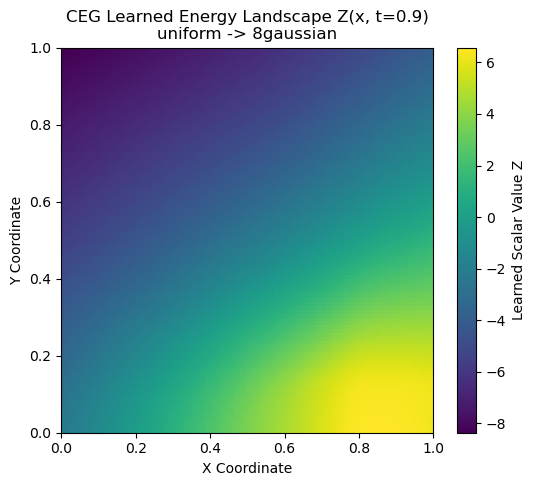

Monte Carlo batch size: 1024
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Monte Carlo batch size: 1024
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Monte Carlo batch size: 1024
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Monte Carlo batch size: 10240
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Monte Carlo batch size: 1024
Loaded latest model: cfm_uniform_8gaussian_20260608_180938.pth
Loaded latest model: guidance_matching_g3_scale_1.0_uniform_8gaussian_20260608_184444.pth


In [44]:
print(f"Re-running inference (no training!) with Batch Size = {EVAL_B}...")

# 2. Extract the configs specifically for the Uniform -> 8-Gaussian task (Index 1)
cfgs_to_eval = [
    guide_cfgs_ceg_cfm[1],
    guide_cfgs_g_sim_MC_cfm[1],
    guide_cfgs_g_cov_a_cfm[1],
    guide_cfgs_g_cov_g_cfm[1],
    guide_cfgs_mc_cfm[1],
    guide_cfgs_gm_cfm[1]
]

# Update the batch size in all baseline configs
for cfg in cfgs_to_eval:
    cfg.ode_cfg.batch_size = EVAL_B
    
# Update our CC-CFM baseline config
cfg_row2.ode_cfg.batch_size = EVAL_B

# 3. Re-sample the trajectories for the baselines
# (This uses the notebook's built-in function to load weights and run the ODE)
traj_ceg_large = sample_and_compute_w2([guide_cfgs_ceg_cfm[1]])[0]
traj_g_sim_MC_large = sample_and_compute_w2([guide_cfgs_g_sim_MC_cfm[1]])[0]
traj_g_cov_a_large = sample_and_compute_w2([guide_cfgs_g_cov_a_cfm[1]])[0]
traj_g_cov_g_large = sample_and_compute_w2([guide_cfgs_g_cov_g_cfm[1]])[0]
traj_mc_large = sample_and_compute_w2([guide_cfgs_mc_cfm[1]])[0]
traj_gm_large = sample_and_compute_w2([guide_cfgs_gm_cfm[1]])[0]

In [49]:
# ============================================================
# Final evaluation:
# Wasserstein distance to p*(x) ∝ p(x) exp(-J(x))
# ============================================================

import pandas as pd
import torch

EVAL_B = 4096
device = cfg_row2.ode_cfg.device

print(f"Computing Wasserstein distances (B={EVAL_B})")


# ------------------------------------------------------------
# Ground-truth guided target:
#
# p*(x) = p(x) exp(-J(x)) / Z
#
# sample_x1_frompeJ already performs sampling from this
# distribution via rejection / importance sampling.
# ------------------------------------------------------------

x1_dist = get_distribution(cfg_row2.dist_pair[1])

x1_true = sample_x1_frompeJ(
    x1_dist.sample,
    x1_dist,
    device,
    B=EVAL_B,
)


# ------------------------------------------------------------
# Generated samples
# ------------------------------------------------------------

generated = {
    "CEG": traj_ceg_large[0][-1],
    "g_sim_MC": traj_g_sim_MC_large[0][-1],
    "g_cov_A": traj_g_cov_a_large[0][-1],
    "g_cov_G": traj_g_cov_g_large[0][-1],
    "MC": traj_mc_large[0][-1],
    "Learned (GM)": traj_gm_large[0][-1],
    "Class-cond. CFM": traj_cc_cfm[-1],
}


# ------------------------------------------------------------
# Wasserstein evaluation
# ------------------------------------------------------------

results = []

with torch.no_grad():
    for name, x_gen in generated.items():

        score = w2(
            x_gen.detach(),
            x1_true.detach(),
        )

        if torch.is_tensor(score):
            score = score.item()

        results.append(
            {
                "Method": name,
                "W2 ↓": score,
            }
        )


df_metrics = (
    pd.DataFrame(results)
    .sort_values("W2 ↓")
    .reset_index(drop=True)
)

df_metrics["W2 ↓"] = df_metrics["W2 ↓"].map("{:.4f}".format)

display(df_metrics)

Computing Wasserstein distances (B=4096)


/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/ot/lp/_network_simplex.py:574: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  check_result(result_code)


,Method,W2 ↓
0,Learned (GM),0.0379
1,g_cov_A,0.1014
2,g_cov_G,0.1027
3,Class-cond. CFM,0.4457
4,g_sim_MC,0.4582
5,MC,0.6320
6,CEG,0.7354
